In [2]:
import os
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [3]:
DATA_DIR = Path("../data/raw/HAM10000")
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

IMAGE_DIRS = [
    DATA_DIR / "HAM10000_images_part_1",
    DATA_DIR / "HAM10000_images_part_2"
]

df = pd.read_csv(METADATA_PATH)

df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [4]:
def find_image(image_id):
    """Find an image in either HAM10000 image folder."""

    for image_dir in IMAGE_DIRS:
        image_path = image_dir / f"{image_id}.jpg"

        if image_path.exists():
            return image_path

    return None

In [5]:
image_id = df.iloc[0]["image_id"]

image_path = find_image(image_id)

print("Image ID:", image_id)
print("Image path:", image_path)
print("Exists:", image_path.exists() if image_path else False)

Image ID: ISIC_0027419
Image path: ..\data\raw\HAM10000\HAM10000_images_part_1\ISIC_0027419.jpg
Exists: True


In [6]:
print("Shape:", df.shape)

Shape: (10015, 7)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  str    
 1   image_id      10015 non-null  str    
 2   dx            10015 non-null  str    
 3   dx_type       10015 non-null  str    
 4   age           9958 non-null   float64
 5   sex           10015 non-null  str    
 6   localization  10015 non-null  str    
dtypes: float64(1), str(6)
memory usage: 990.6 KB


In [8]:
df.describe()

,age
count,9958.000000
mean,51.863828
std,16.968614
min,0.000000
25%,40.000000
50%,50.000000
75%,65.000000
max,85.000000


In [9]:
df.isnull().sum()

lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64

In [10]:
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percentage)

age             0.569146
image_id        0.000000
lesion_id       0.000000
dx              0.000000
dx_type         0.000000
sex             0.000000
localization    0.000000
dtype: float64


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
class_counts = df["dx"].value_counts()

print(class_counts)

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


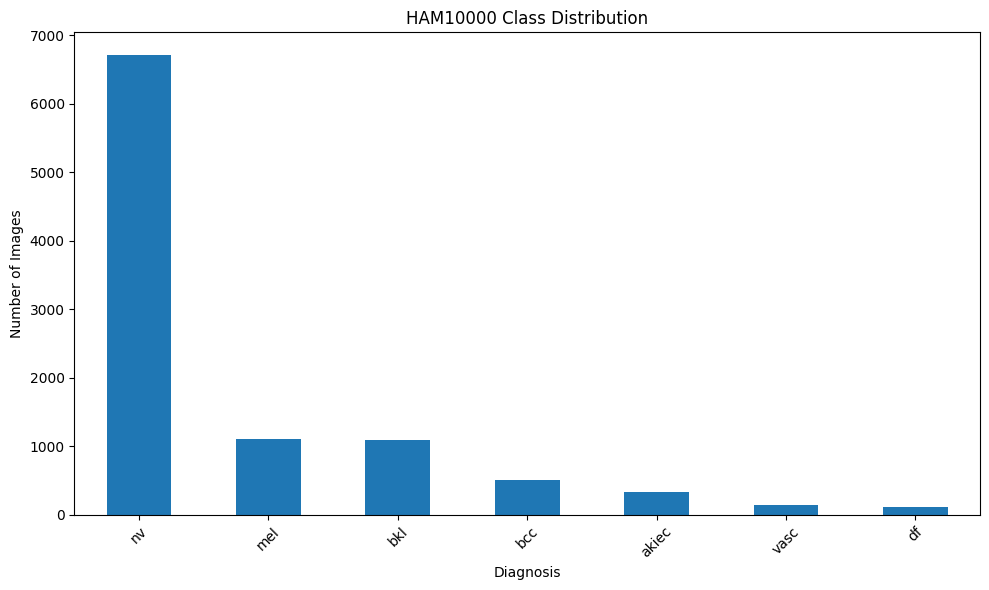

In [13]:
plt.figure(figsize=(10, 6))

class_counts.plot(kind="bar")

plt.title("HAM10000 Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("../figures/eda/class_distribution.png", dpi=300)
plt.show()


In [14]:
class_names = {
    "akiec": "Actinic keratoses / Bowen's disease",
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions",
    "df": "Dermatofibroma",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
    "vasc": "Vascular lesions"
}

In [15]:
class_distribution = (
    df["dx"]
    .value_counts()
    .rename_axis("class")
    .reset_index(name="count")
)

class_distribution["class_name"] = (
    class_distribution["class"].map(class_names)
)

class_distribution

,class,count,class_name
0,nv,6705,Melanocytic nevi
1,mel,1113,Melanoma
2,bkl,1099,Benign keratosis-like lesions
3,bcc,514,Basal cell carcinoma
4,akiec,327,Actinic keratoses / Bowen's disease
5,vasc,142,Vascular lesions
6,df,115,Dermatofibroma


In [16]:
IMAGE_DIR = DATA_DIR / "images"

In [17]:
def get_image_path(image_id):
    return IMAGE_DIR / f"{image_id}.jpg"

In [18]:
sample_per_class = (
    df.groupby("dx", group_keys=False)
      .head(3)
)

sample_per_class.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
64,HAM_0001751,ISIC_0024698,nv,consensus,70.0,male,face
1095,HAM_0005276,ISIC_0027008,df,histo,75.0,male,back


In [19]:
found = 0
not_found = 0

for image_id in df["image_id"]:

    image_path = find_image(image_id)

    if image_path is not None:
        found += 1
    else:
        not_found += 1

print("Images found:", found)
print("Images not found:", not_found)

Images found: 10015
Images not found: 0


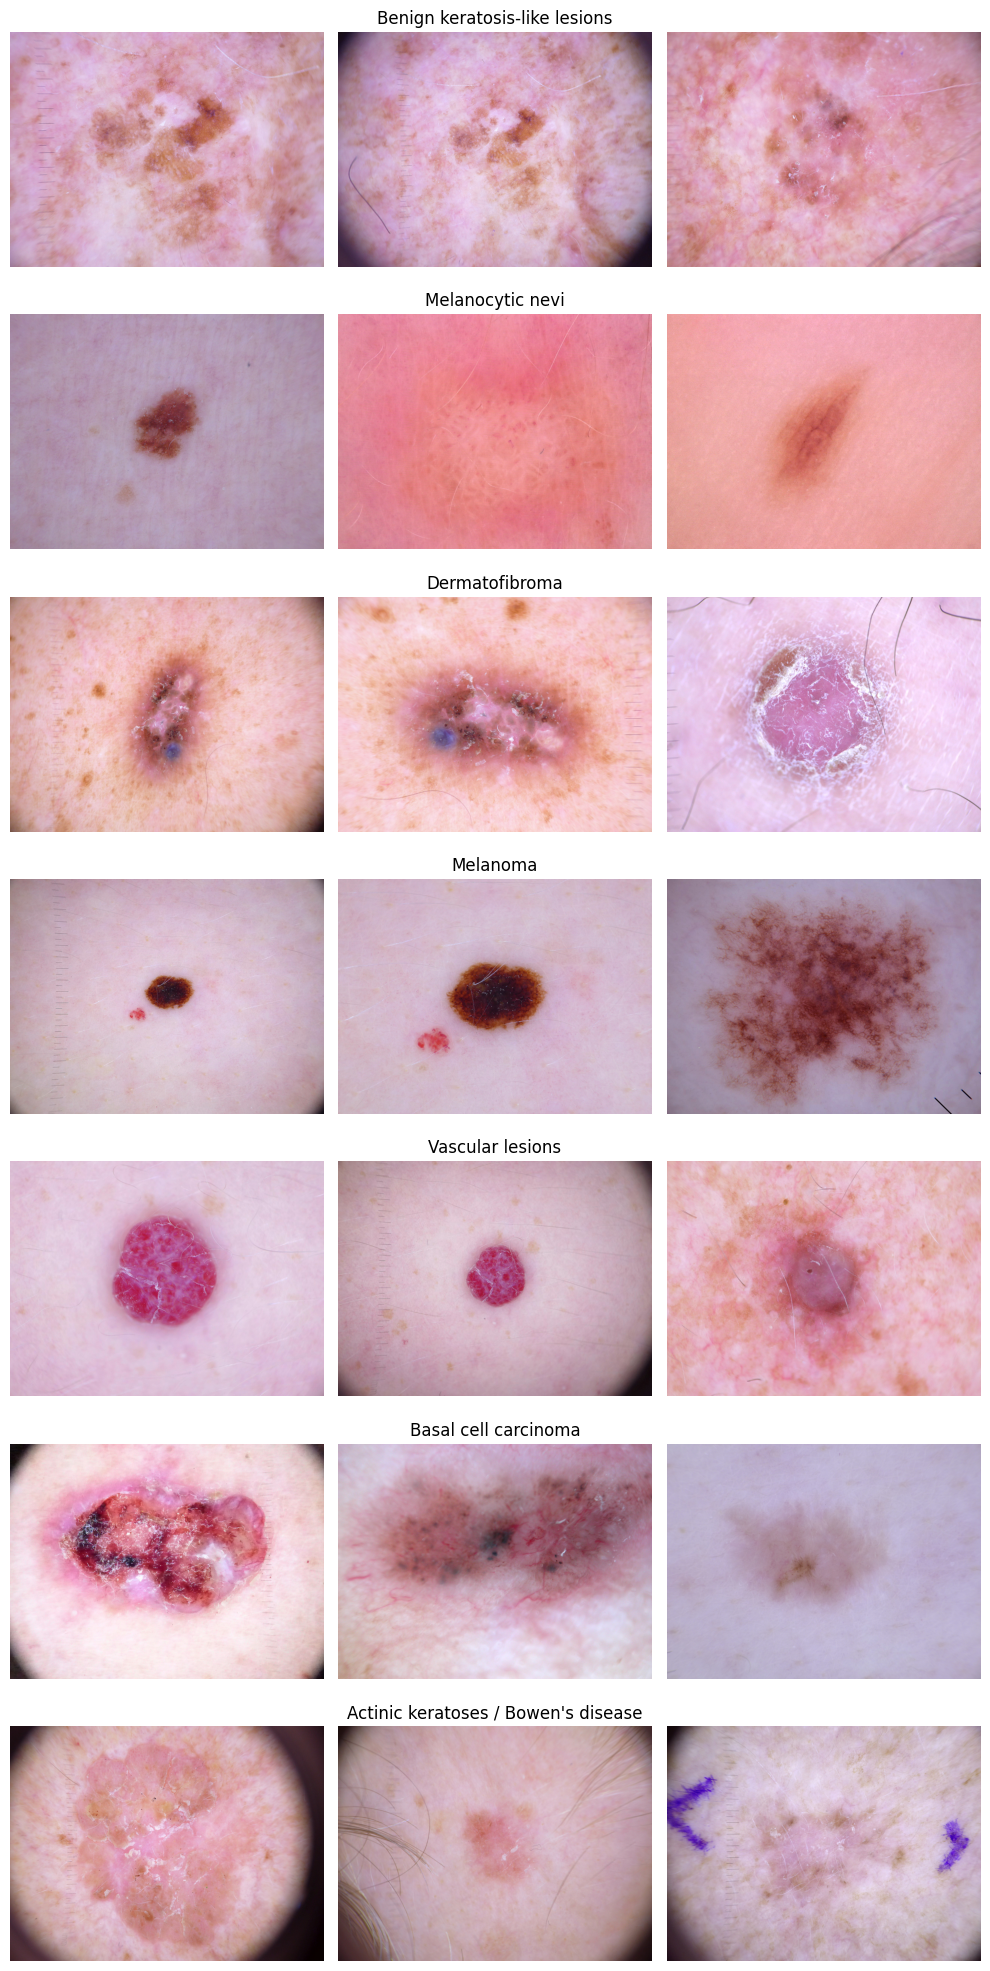

In [20]:
class_codes = df["dx"].unique()

fig, axes = plt.subplots(
    len(class_codes),
    3,
    figsize=(10, 20)
)

for row, class_code in enumerate(class_codes):

    samples = df[df["dx"] == class_code].head(3)

    for col, (_, sample) in enumerate(samples.iterrows()):

        image_path = find_image(sample["image_id"])

        if image_path is not None:

            image = Image.open(image_path)

            axes[row, col].imshow(image)
            axes[row, col].axis("off")

            if col == 1:
                axes[row, col].set_title(
                    class_names.get(class_code, class_code)
                )

        else:
            axes[row, col].text(
                0.5,
                0.5,
                "Image not found",
                ha="center",
                va="center"
            )
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [21]:
image_dimensions = []

for image_id in df["image_id"]:

    image_path = find_image(image_id)

    if image_path is None:
        continue

    try:
        with Image.open(image_path) as image:

            image_dimensions.append({
                "image_id": image_id,
                "width": image.width,
                "height": image.height,
                "mode": image.mode
            })

    except Exception as e:
        print(f"Error reading {image_id}: {e}")

dimensions_df = pd.DataFrame(image_dimensions)

dimensions_df.head()

,image_id,width,height,mode
0,ISIC_0027419,600,450,RGB
1,ISIC_0025030,600,450,RGB
2,ISIC_0026769,600,450,RGB
3,ISIC_0025661,600,450,RGB
4,ISIC_0031633,600,450,RGB


In [22]:
dimensions_df[["width", "height"]].describe()

,width,height
count,10015.0,10015.0
mean,600.0,450.0
std,0.0,0.0
min,600.0,450.0
25%,600.0,450.0
50%,600.0,450.0
75%,600.0,450.0
max,600.0,450.0


In [23]:
dimensions_df.groupby(
    ["width", "height"]
).size().sort_values(ascending=False)

width  height
600    450       10015
dtype: int64

In [24]:
corrupted_images = []
missing_images = []

for image_id in df["image_id"]:

    image_path = find_image(image_id)

    if image_path is None:
        missing_images.append(image_id)
        continue

    try:
        with Image.open(image_path) as image:
            image.verify()

    except Exception as e:
        corrupted_images.append({
            "image_id": image_id,
            "error": str(e)
        })

print("Missing images:", len(missing_images))
print("Corrupted images:", len(corrupted_images))

Missing images: 0
Corrupted images: 0


In [25]:
df["age"].describe()

count    9958.000000
mean       51.863828
std        16.968614
min         0.000000
25%        40.000000
50%        50.000000
75%        65.000000
max        85.000000
Name: age, dtype: float64

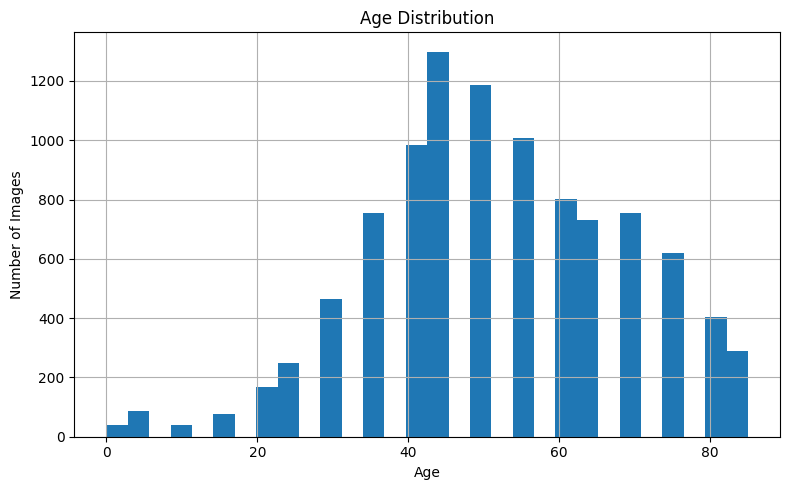

In [26]:
plt.figure(figsize=(8, 5))

df["age"].hist(bins=30)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.savefig("../figures/eda/age_distribution.png", dpi=300)
plt.show()

In [27]:
print(df["sex"].value_counts(dropna=False))

sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64


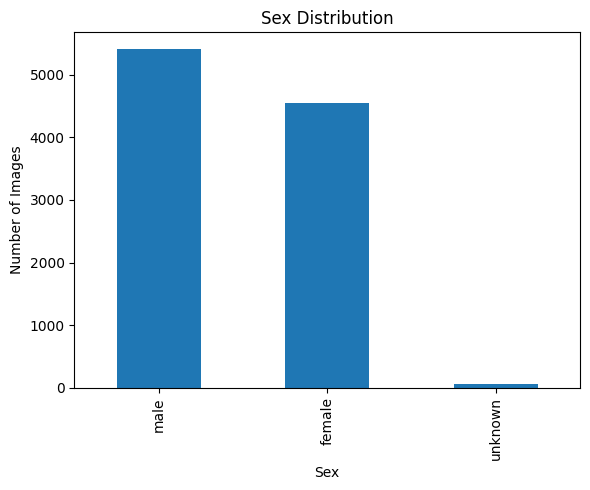

In [31]:
plt.figure(figsize=(6, 5))

df["sex"].value_counts(dropna=False).plot(kind="bar")

plt.title("Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.savefig("../figures/eda/sex_distribution.png", dpi=300)
plt.show()

In [29]:
print(df["localization"].value_counts(dropna=False))

localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
scalp               128
hand                 90
ear                  56
genital              48
acral                 7
Name: count, dtype: int64


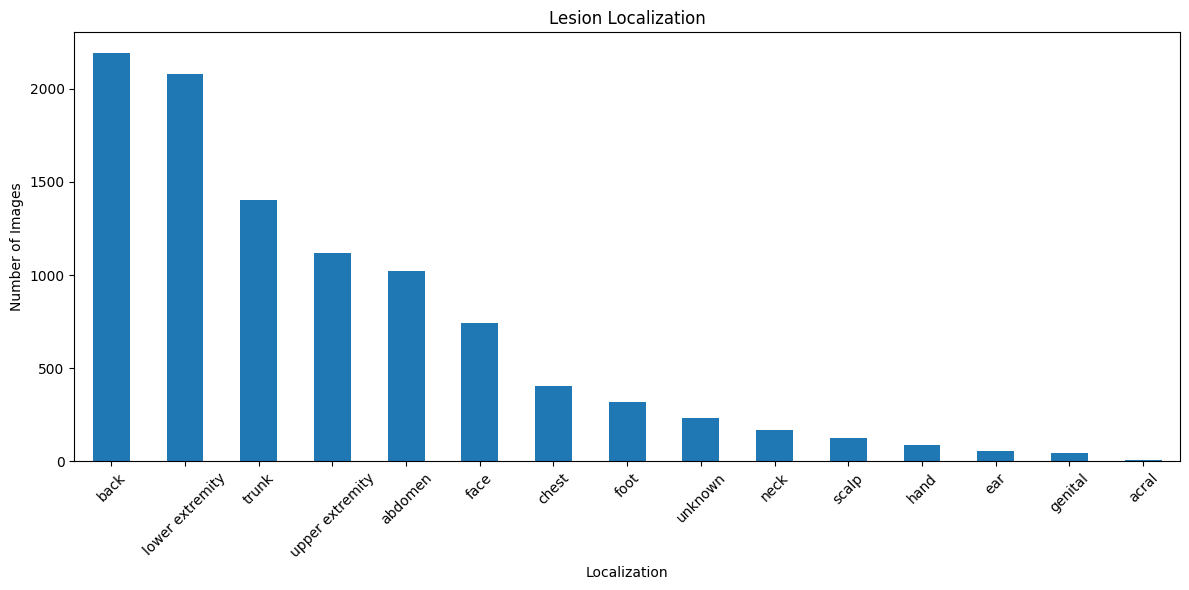

In [32]:
plt.figure(figsize=(12, 6))

df["localization"].value_counts().plot(kind="bar")

plt.title("Lesion Localization")
plt.xlabel("Localization")
plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../figures/eda/lesion_location.png", dpi=300)
plt.show()